In [1]:
# Delete first two lines for the code to run in local machine
import os
os.chdir(r'D:\01 KTH\02 Academics\03 Sem 3\01 P5\02 SM2001_Data Driven methods\04 Projects\02 Pitched-plate dataset')
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

UV=np.load('UV.npy')
x=np.load('x.npy')
y=np.load('y.npy')

# 1. Visualising flow and plotting relevant flow properties

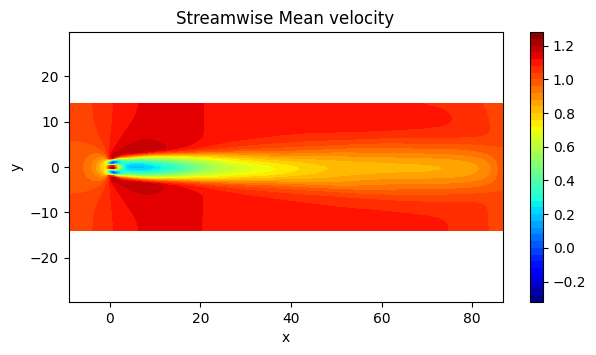

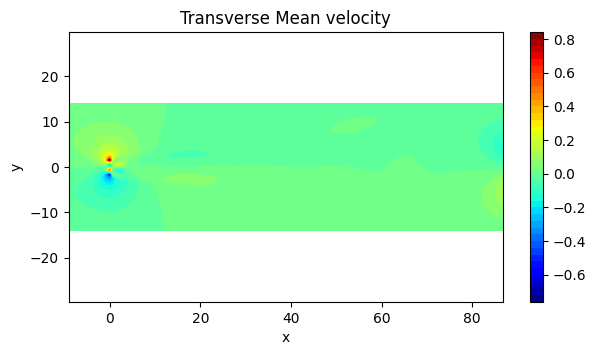

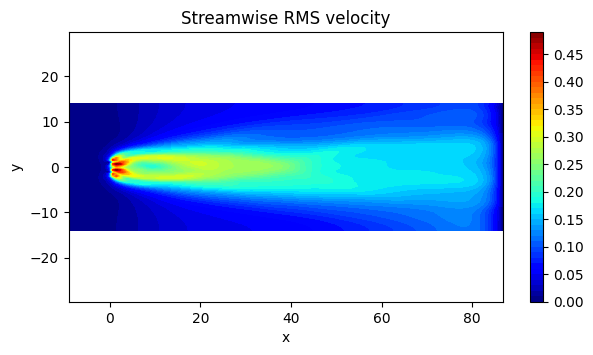

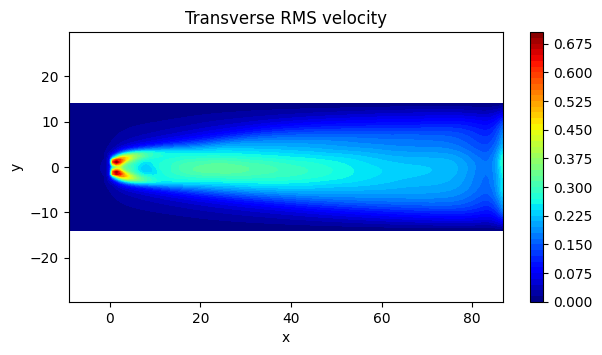

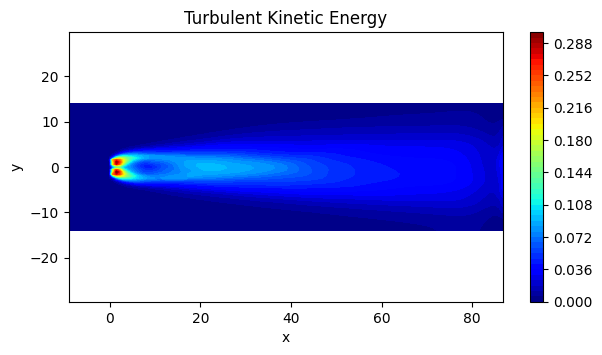

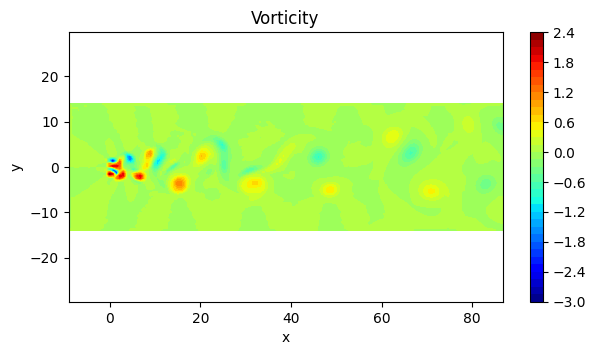

In [2]:
u= UV[:, :, :,0]      # streamwise velocity component
v= UV[:, :, :,1]      #transverse velocity component

#statistics of the flow field
u_mean= np.mean(u,axis=0)                                                             #time average streamwise velocity
v_mean=np.mean(v,axis=0)                                                              #time average transverse velocity
u_fluc= u-u_mean                                                                      # fluctuating streamwise velocity
v_fluc= v-v_mean                                                                      # fluctuating transverse velocity
u_rms= np.sqrt(np.mean(u_fluc**2,axis=0))                                             # root mean square of streamwise velocity
v_rms= np.sqrt(np.mean(v_fluc**2,axis=0))                                             # root mean square of transverse velocity
tke= 0.5*(u_rms**2+v_rms**2)                                                          #turbulent kinetic energy

dx= x[1,0]-x[0,0]
dy= y[0,1]-y[0,0]
omega_z= np.gradient(v,dx,axis=1)-np.gradient(u,dy,axis=2)                            # vorticity

def contour(field,title,cmap="jet",levels=50):
    plt.figure(figsize=(7,3.5))
    plt.contourf(x,y,field,levels=levels,cmap=cmap)
    plt.colorbar()
    plt.title(title)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.axis('equal')
    #plt.tight_layout()

contour(u_mean,"Streamwise Mean velocity")
contour(v_mean,"Transverse Mean velocity")
contour(u_rms,"Streamwise RMS velocity")
contour(v_rms,'Transverse RMS velocity')
contour(tke,'Turbulent Kinetic Energy')
contour(omega_z[0,:,:],'Vorticity')
plt.show()

# 2. Calculating POD and DMD mode for dataset and Reconstructing flow for different level of truncation

Number of modes needed for 90% energy capture: 69
Number of modes needed for 99% energy capture: 220


Text(0.5, 0, 'snapshot')

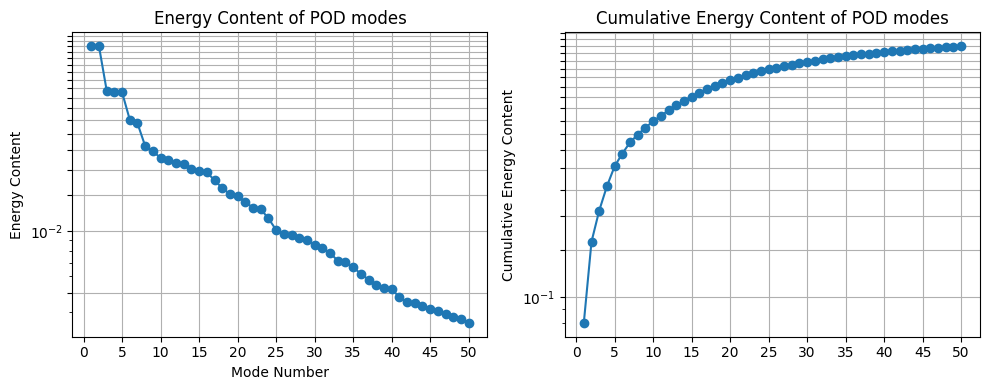

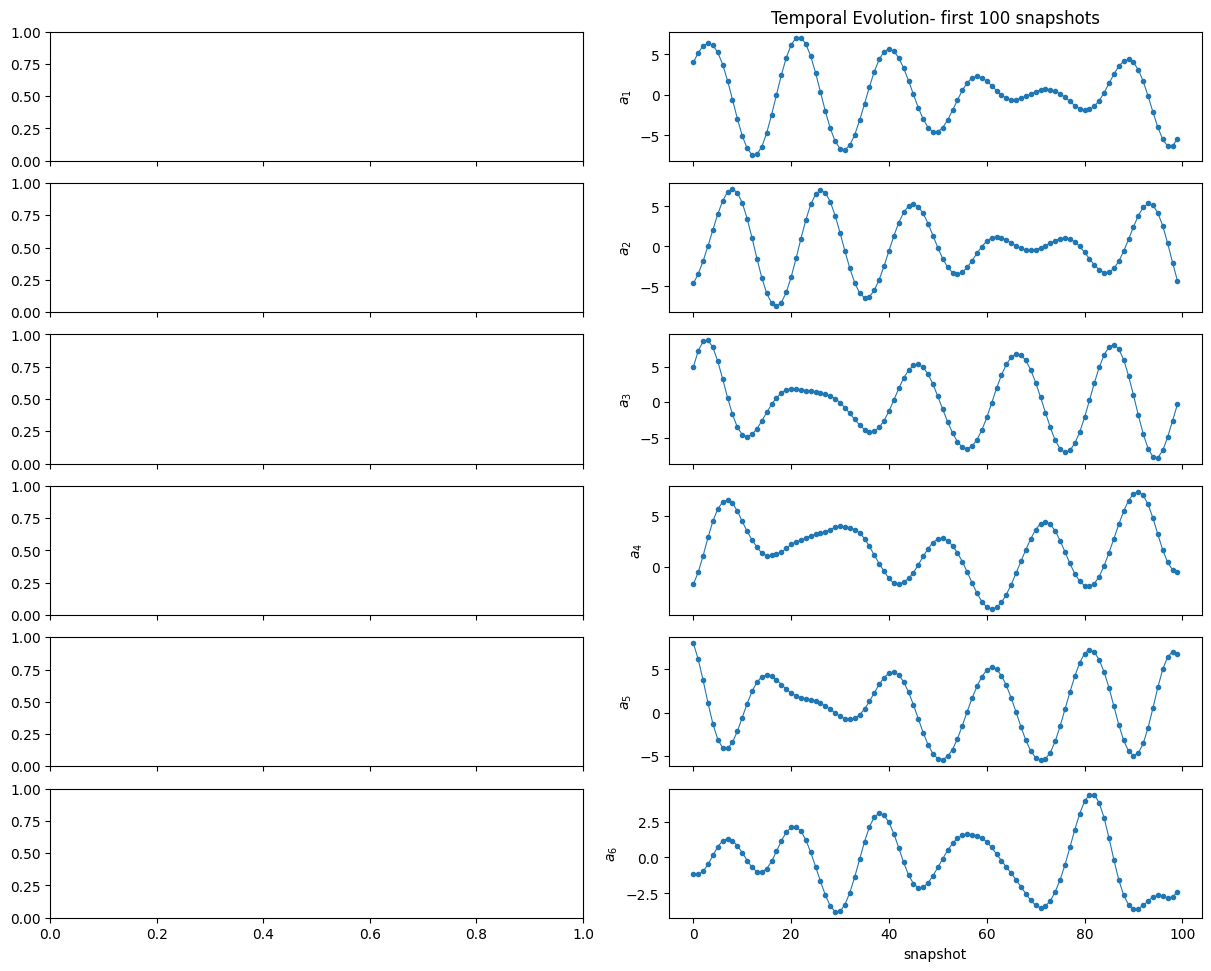

In [3]:
# POD of the flow field
Xf=np.stack([u_fluc,v_fluc],axis=-1)
Xf= Xf.reshape(1000,-1)
Xf= np.transpose(Xf)

Xbar=np.stack([u_mean,v_mean],axis=-1)
Xbar= Xbar.reshape(-1,1)
#Xbar= np.transponse(Xbar)

#Econmoy SVD
U_pod,S,Vt= np.linalg.svd(Xf,full_matrices=False)           # POD of Xf

# Calculating the POD modes 
energy= S**2/np.sum(S**2)
cum_energy= np.cumsum(energy)

#plotting the energy content of the POD modes

modes= np.arange(1,len(S)+1)

fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].semilogy(modes[:50],energy[:50],'o-')
ax[0].set_xlabel('Mode Number'); ax[0].set_ylabel('Energy Content')
ax[0].set_title('Energy Content of POD modes')
ax[0].grid(True)
ax[0].xaxis.set_major_locator(MultipleLocator(5))
ax[0].yaxis.set_major_locator(MultipleLocator(0.005))   

ax[1].semilogy(modes[:50],cum_energy[:50],'o-')
ax[1].set_label('Mode Number'); ax[1].set_ylabel('Cumulative Energy Content')
ax[1].set_title('Cumulative Energy Content of POD modes')
ax[1].grid(True)
ax[1].xaxis.set_major_locator(MultipleLocator(5))
ax[1].yaxis.set_major_locator(MultipleLocator(0.05))
plt.tight_layout()

#modes need for 90% and 99% energy content
r90= np.where(cum_energy>=0.9)[0][0]+1
r99= np.where(cum_energy>=0.99)[0][0]+1
print(f'Number of modes needed for 90% energy capture:',r90)
print(f'Number of modes needed for 99% energy capture:',r99)

# Temporal coefficients
nm = 6                                              # modes to show
Nt= Xf.shape[1]
coef = (S[:nm, None] * Vt[:nm, :])                  # (nm, Nt): row k is the time history of mode k, with its energy weight
tt = np.arange(Nt)

fig, axs = plt.subplots(nm, 2, figsize=(12, 1.6*nm), constrained_layout=True, sharex="col")
for m, (ax_l, ax_r) in enumerate(axs):
    #ax_l.plot(tt, coef[m], lw=0.8);               
    ax_r.set_ylabel(f"$a_{m+1}$")
    ax_r.plot(tt[:100], coef[m, :100], "o-", ms=3, lw=0.8)       # zoom: count the period by eye
#axs[0, 0].set_title("Temporal Evolution of POD modes"); 
axs[0, 1].set_title("Temporal Evolution- first 100 snapshots")
#axs[-1, 0].set_xlabel("snapshot"); 
axs[-1, 1].set_xlabel("snapshot")

# DMD reconstruction of flow field

(16384, 999) (999,) (999, 999)
eigenvalues of the DMD modes: [0.91802158+0.39287589j 0.91802158-0.39287589j 0.94297675+0.3303432j
 0.94297675-0.3303432j  0.95919288+0.26866929j 0.95919288-0.26866929j
 0.97755236+0.14769561j 0.97755236-0.14769561j 0.99438051+0.j
 0.97336692+0.j        ]
Frequency of the DMD modes: [ 0.06435821 -0.06435821  0.05362877 -0.05362877  0.04346534 -0.04346534
  0.02386576 -0.02386576  0.          0.        ]
Growth rate of the DMD modes: [-0.00144454 -0.00144454 -0.0008348  -0.0008348  -0.00389807 -0.00389807
 -0.01141808 -0.01141808 -0.00563534 -0.02699416]


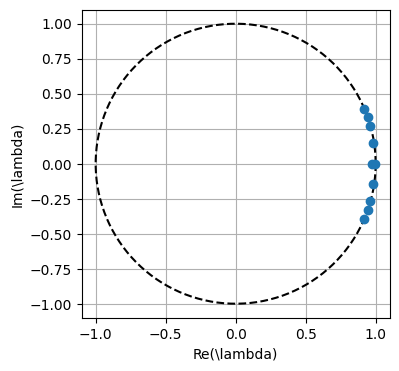

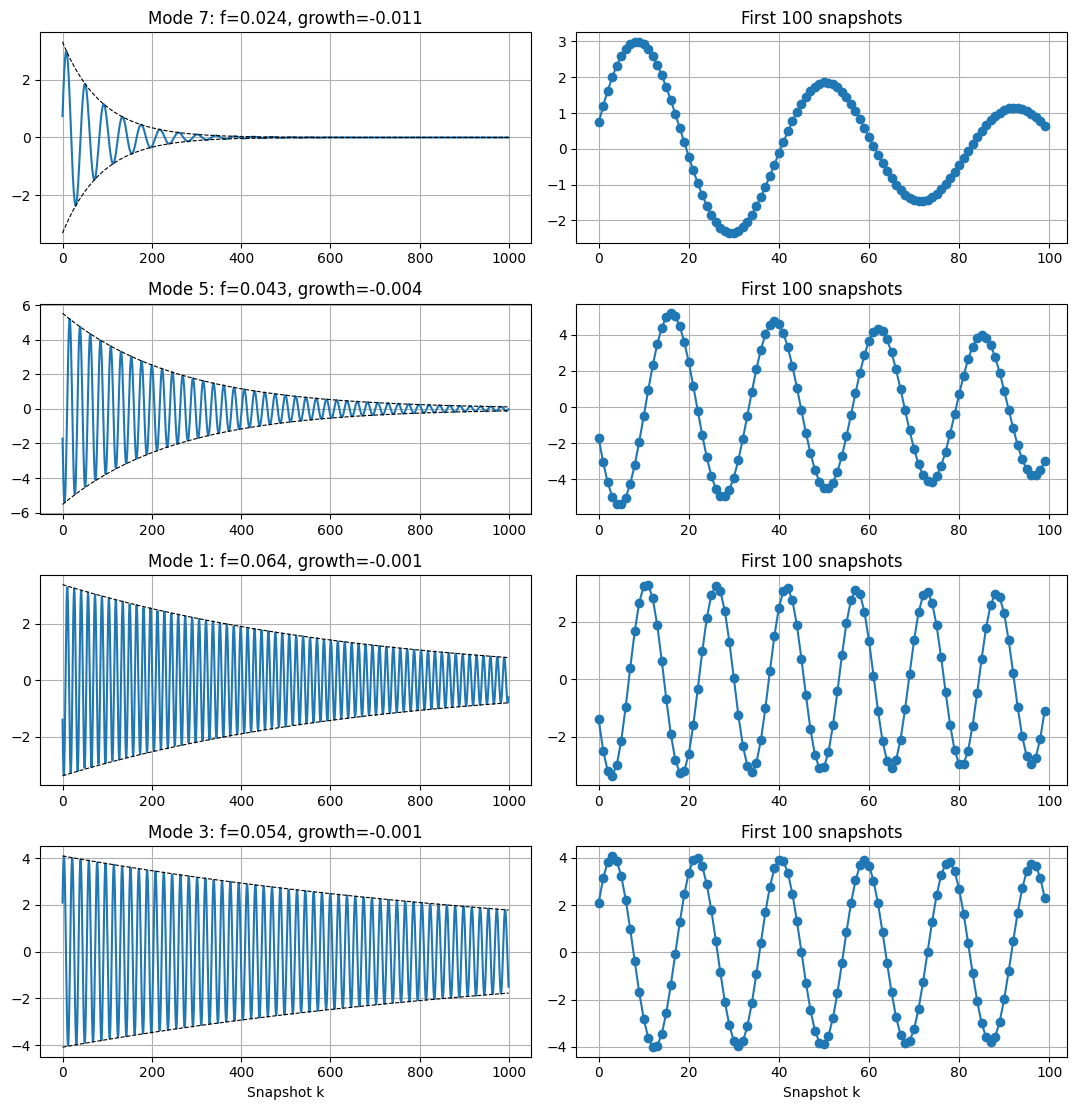

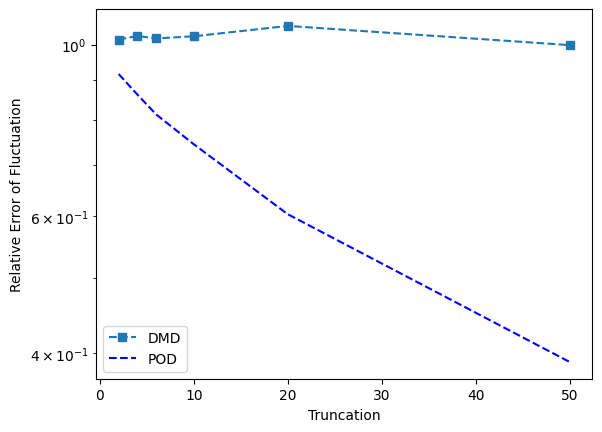

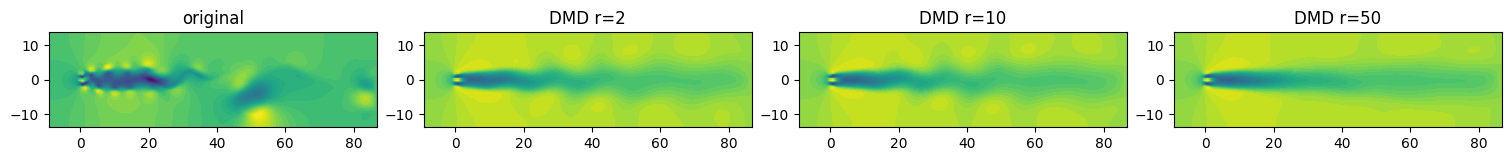

In [ ]:
X1= Xf[:,:-1]
X1prime= Xf[:,1:]

U1,S1,V1t= np.linalg.svd(X1,full_matrices=False)                                                     # rank of the matrix X1
r= 10                                                                                                 # Chosen rank from energy content of the POD modes, even number of modes considered for consructing conjugate pairs
print(np.shape(U1),np.shape(S1),np.shape(V1t))
Ur= U1[:,:r]                                                                                         # U1 holds spatial vectors as columns, hence transpose not required
Sigmar = np.diag(S1[:r])                                                                             # Sr is a diagonal matrix of singular values, np.diag() used to construct diagonal square matrix
Vr= V1t[:r,:].T                                                                                      # Transpose of Vr taken to get temporal vectors as columns
#print(np.shape(Ur),np.shape(Sigmar),np.shape(Vr))

Atilde= np.linalg.solve(Sigmar.T,(Ur.T@X1prime@Vr).T).T
Lambda,W= np.linalg.eig(Atilde)                                                                       # Reduced order linear operator
print('eigenvalues of the DMD modes:', Lambda)

# plotting eigenvalues of the DMD modes
theta= np.linspace(0, 2*np.pi,400)
plt.figure(figsize=(4,4))
plt.plot(np.cos(theta),np.sin(theta),'k--')
plt.plot(Lambda.real,Lambda.imag,'o')
plt.gca().set_aspect('equal'); plt.xlabel(r'Re(\lambda)'); plt.ylabel(r'Im(\lambda)')
plt.grid(True)

dt= 1.0
freq= np.angle(Lambda)/(2*np.pi*dt)
egrowth= np.log(np.abs(Lambda))/dt
print(f'Frequency of the DMD modes:',freq)
print(f'Growth rate of the DMD modes:',growth)

Phi= X1prime@Vr@ np.linalg.inv(Sigmar)@W
#print(np.shape(Phi))

b= np.linalg.lstsq(Phi,X1[:,0], rcond=None)[0]                                                                                  # amplitudes of the DMD modes
#print(b.shape)

Nt= Xf.shape[1]
time_dyn= np.array([b*Lambda**t for t in range(Nt)]).T
#print(np.shape(time_dyn))

idx= np.where(Lambda.imag>0)[0]                                                                                           # Assigning one index for each conjugate pair
idx=idx[np.argsort(np.abs(Lambda[idx]))]                                                                                   # Sorting the indices in ascending order of freuqency
npairs= len(idx)
k= np.arange(Nt)
fig,axes=plt.subplots(npairs,2,figsize=(11,2.8*npairs),squeeze=False)
for row,j in enumerate(idx):
    sig=time_dyn[j]
    theta=np.angle(Lambda[j])
    env= np.abs(b[j])*np.abs(Lambda[j])**k
    axes[row,0].plot(k,sig.real)
    axes[row,0].plot(k,env,"--",color="k",lw=0.8)
    axes[row,0].plot(k,-env,"--",color="k",lw=0.8)
    axes[row,0].set_title(f"Mode {j+1}: f={freq[j]:.3f}, growth={growth[j]:.3f}")
    axes[row,0].grid(True)

    axes[row,1].plot(k[:100],sig.real[:100],'o-')
    axes[row,1].set_title("First 100 snapshots")
    axes[row,1].grid(True)
axes[-1,0].set_xlabel("Snapshot k"); axes[-1,1].set_xlabel("Snapshot k")
plt.tight_layout()

# Reconstructing the flow
def recon(r_):
    Ur_=U1[:,:r_]
    Sr_=np.diag(S1[:r_])
    Vr_= V1t[:r_,:].T
    At_=np.linalg.solve(Sr_.T,(Ur_.T@X1prime@Vr_).T).T
    lam_,W_=np.linalg.eig(At_)
    Phi_=X1prime@Vr_@np.linalg.inv(Sr_)@W_
    b_=np.linalg.lstsq(Phi_,Xf[:,0].astype(complex),rcond=None)[0]
    dyn_=b_[:,None]*lam_[:,None]**k[None,:]
    return (Phi_@dyn_).real,lam_

def recon_pod(r_):
    Xr= U_pod[:,:r_]@(S[:r_,None]*Vt[:r_,:])
    err= np.linalg.norm(Xf-Xr)/np.linalg.norm(Xf)
    return err

def to_u(Xcols):
    n_t=Xcols.shape[1]
    return Xcols.T.reshape(n_t,128,64,2)[...,0]

r1= [2,4,6,10,20,50]
err_dmd,lam_max=[],[]
err_pod=[]
for r_ in r1:
    Xd_,lam_=recon(r_)
    err_dmd.append(np.linalg.norm(Xf-Xd_)/np.linalg.norm(Xf))
    lam_max.append(np.abs(lam_).max())
    err_pod.append(recon_pod(r_))

plt.figure()
plt.semilogy(r1,err_dmd,"s--",label="DMD")
plt.semilogy(r1,err_pod,"b--",label="POD")
plt.xlabel("Truncation");plt.ylabel("Relative Error of Fluctuation");plt.legend()

t0=500
fig,axs= plt.subplots(1,4,figsize=(15,3.2), constrained_layout=True)
axs[0].contourf(x, y, to_u((Xbar + Xf)[:, [t0]])[0], levels=40); axs[0].set_title("original")
for axi, r_ in zip(axs[1:], [2, 10, 50]):
    axi.contourf(x, y, to_u(recon(r_)[0][:, [t0]] + Xbar)[0], levels=40)
    axi.set_title(f"DMD r={r_}")
for axi in axs: axi.set_aspect("equal")
plt.show()


# 3. Modal Decomposition based on autoencoders

0 1.008001297712326 0.9882436990737915
10 0.7447664923965931 0.7246965169906616
20 0.5365392342209816 0.6431630849838257
30 0.4383110608905554 0.6612136960029602
40 0.37470670975744724 0.7043144702911377
50 0.3317030668258667 0.7390890717506409
60 0.3016061894595623 0.7644023299217224
70 0.2804681099951267 0.7752168774604797
80 0.26463181897997856 0.8003522753715515
90 0.2499408833682537 0.8135673999786377
100 0.23999126255512238 0.8212010860443115
110 0.23069741390645504 0.8287637233734131
120 0.2223275639116764 0.8390688896179199
130 0.21627021860331297 0.8467381000518799
140 0.21457885392010212 0.8470987677574158


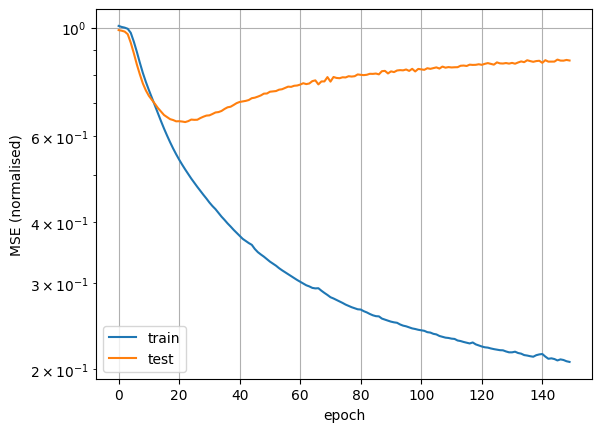

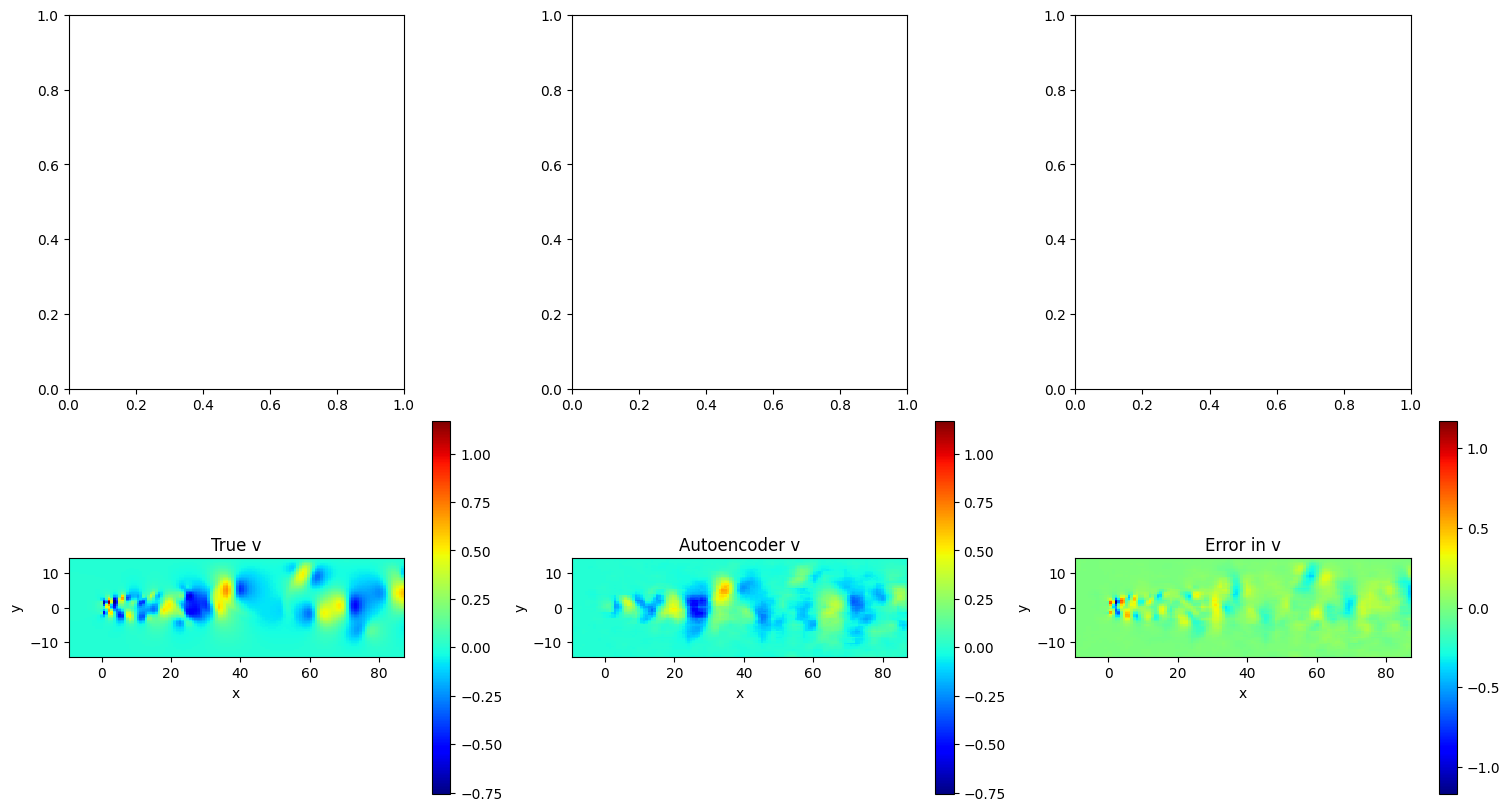

In [5]:
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
snaps= Xf.T
snaps=snaps.reshape(Nt,128,64,2)
data=snaps.transpose(0,3,1,2)

#print(data.shape)
#print(np.allclose(data[10,0],u_fluc[10]))
#print(np.allclose(data[10,1], v_fluc[10]))

ntrain= 800
train,test= data[:ntrain],data[ntrain:]

scale= np.std(train)
#print(scale)
train_n, test_n= train/scale, test/scale
#print(train_n.shape, test_n.shape, train_n.std())

r_ae=10                                                                                   # Same r as POD,DMD
class AE(nn.Module):
    def __init__(self,latent_dim):
        super().__init__()
        self.enc= nn.Sequential(
                nn.Conv2d(2,16,3,stride=2,padding=1),nn.GELU(),                           # Matrix size after 1st layer encoder (16,64,32)
                nn.Conv2d(16,32,3, stride=2,padding=1),nn.GELU(),                         # Matrix size after 2nd layer encoder (32,32,16)
                nn.Conv2d(32,64,3,stride=2,padding=1),nn.GELU(),                          # Matrix size after 3rd layer encoder (64,16,8)
                nn.Flatten(),
                nn.Linear(64*16*8,latent_dim)
            )
        self.dec_fc= nn.Sequential(nn.Linear(latent_dim,64*16*8),nn.GELU())
        self.dec= nn.Sequential(
                  nn.ConvTranspose2d(64,32,3,stride=2,padding=1,output_padding=1),nn.GELU(),
                  nn.ConvTranspose2d(32,16,3,stride=2,padding=1,output_padding=1),nn.GELU(),
                  nn.ConvTranspose2d(16,2,3,stride=2,padding=1,output_padding=1)
            )
    h= torch.arange(24).float().reshape(2,12)
                
    def forward(self,s):
        z=self.enc(s)                                                               # (batch,latent_dim)
        h= self.dec_fc(z)                                                           # (batch, 8192)
        h= h.reshape(-1,64,16,8)
        return self.dec(h),z

train_t= torch.tensor(train_n, dtype=torch.float32)
test_t= torch.tensor(test_n, dtype=torch.float32)

train_loader = DataLoader(TensorDataset(train_t),batch_size=150, shuffle=True)

model= AE(latent_dim=r_ae)
loss_fn= nn.MSELoss()
opt= torch.optim.Adam(model.parameters(), lr=1e-3)
n_epochs= 150
train_hist, test_hist=[],[]
for epoch in range(n_epochs):
    model.train()
    running=0.0
    for (batch,) in train_loader:
        xhat,z= model(batch)
        loss= loss_fn(xhat,batch)
        opt.zero_grad()
        loss.backward()
        opt.step()
        running+=loss.item()*batch.shape[0]
    train_hist.append(running/len(train_t))
    model.eval()
    with torch.no_grad():
        xhat_te,_=model(test_t)
        test_hist.append(loss_fn(xhat_te,test_t).item())
    if epoch % 10==0:
        print(epoch, train_hist[-1], test_hist[-1])
plt.figure()
plt.semilogy(train_hist, label="train")
plt.semilogy(test_hist, label="test")
plt.xlabel("epoch"); plt.ylabel("MSE (normalised)"); plt.legend()
plt.grid(True)

flow_rec= xhat_te.cpu().numpy()*scale
u_rec=flow_rec[:,0,:,:]
v_rec=flow_rec[:,1,:,:]

j=0
orig=test_t[j].cpu().numpy()*scale
r_ae=flow_rec[j]
fig,axes=plt.subplots(2,3,figsize=(15,8),constrained_layout=True)
for c,name in enumerate(["u","v"]):
    field_tr=orig[c]
    rec_field=r_ae[c]
    error_field=rec_field-field_tr

    vmin=min(field_tr.min(),rec_field.min())
    vmax=max(field_tr.max(),rec_field.max())
    if vmin==vmax:
        vmax=vmin+1e-8
    error_max=max(float(np.abs(error_field).max()),1e-8)
    fields = [field_tr, rec_field, error_field]
    titles=[f"True {name}",f"Autoencoder {name}",f"Error in {name}"]
for col in range(3):
    ax=axes[c,col]
    limits=(dict(vmin=vmin,vmax=vmax) if col<2 else dict(vmin=-error_max,vmax=error_max))
    im=ax.pcolormesh(x,y,fields[col],shading="auto",cmap="jet",**limits,)
    ax.set_title(titles[col])
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
    fig.colorbar(im,ax=ax)
plt.show()

    

# 4. Use LSTM to predict the temporal evolution of the leading POD coefficients. Reconstruct the flow from the predicted coefficients and compare the temporal mean and the RMS velocity fluctuations of the predicted and the original fields. 

(1000, 10)
True
torch.Size([782, 18, 10]) torch.Size([782, 10])
True
True
torch.Size([5, 10])
0 0.9166120260267916 0.6944219470024109
10 0.017188115169287033 0.017845621332526207
20 0.006408433344148461 0.0065139648504555225
30 0.004101348443009207 0.004208194091916084
40 0.002872763298656744 0.0028803960885852575
50 0.0022852154367643852 0.0021854517981410027
60 0.0019037734962466274 0.001866235863417387
70 0.0015022359395999928 0.0014822431840002537
80 0.0014252713012039813 0.0013223206624388695
90 0.0011020135610838376 0.001160346087999642
(16384, 200) (16384, 200) (16384, 200)


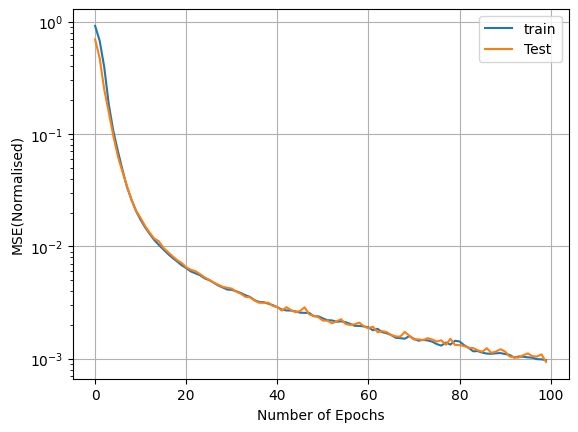

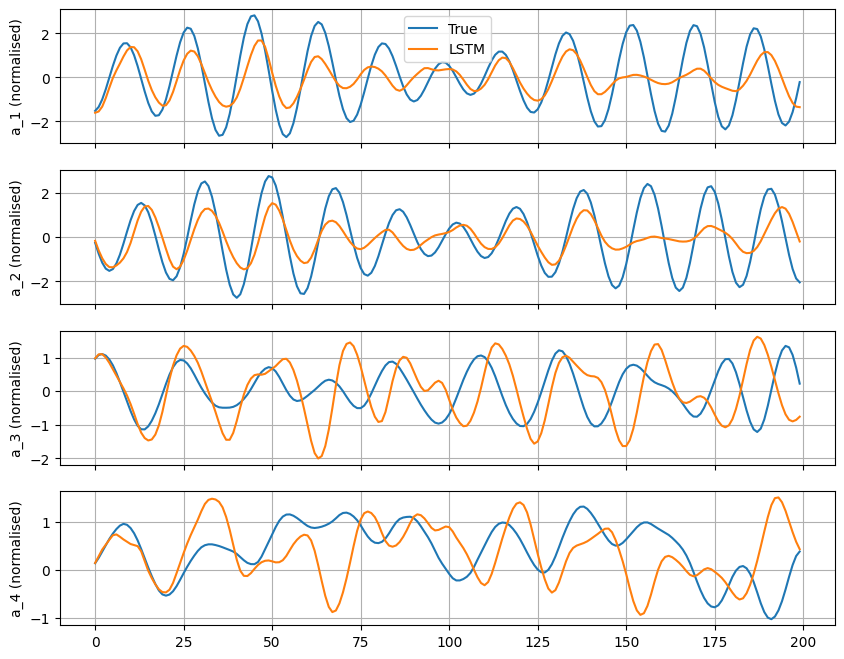

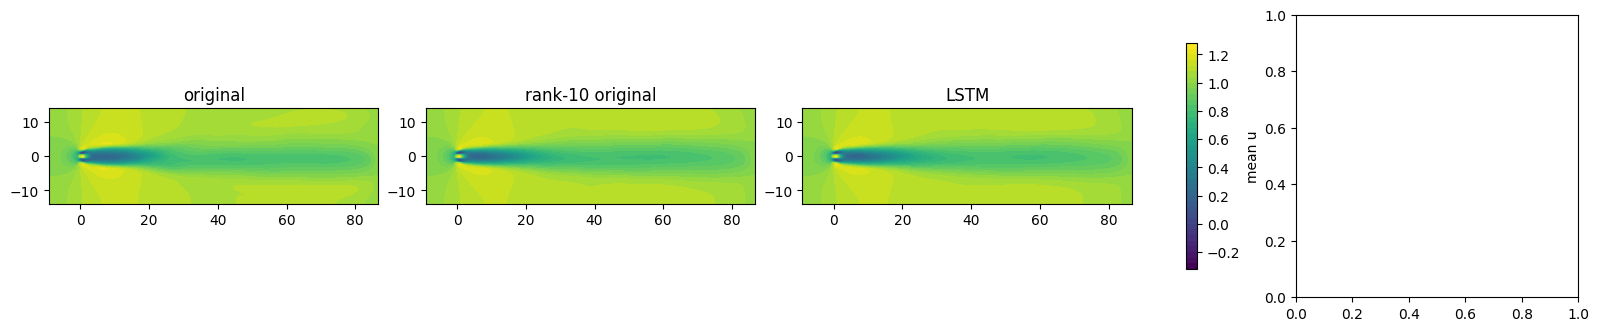

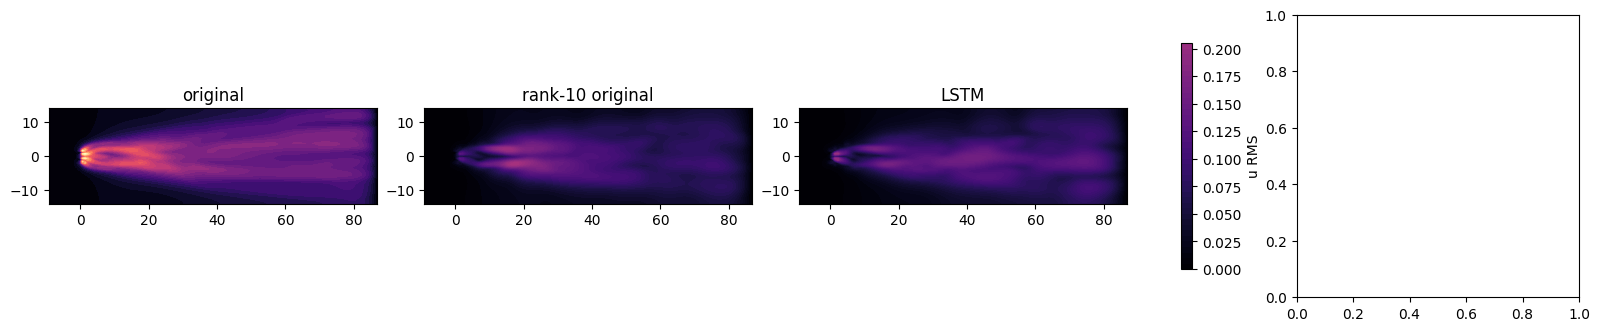

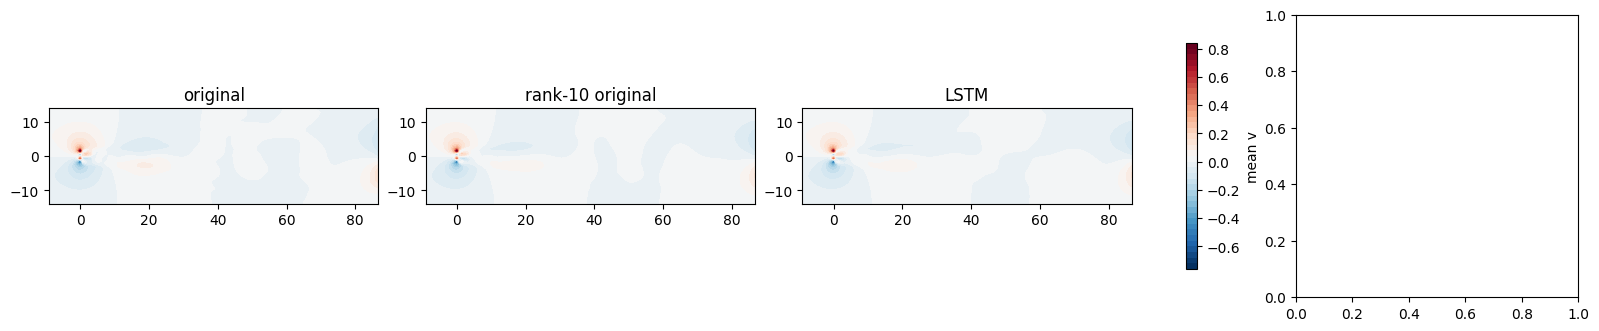

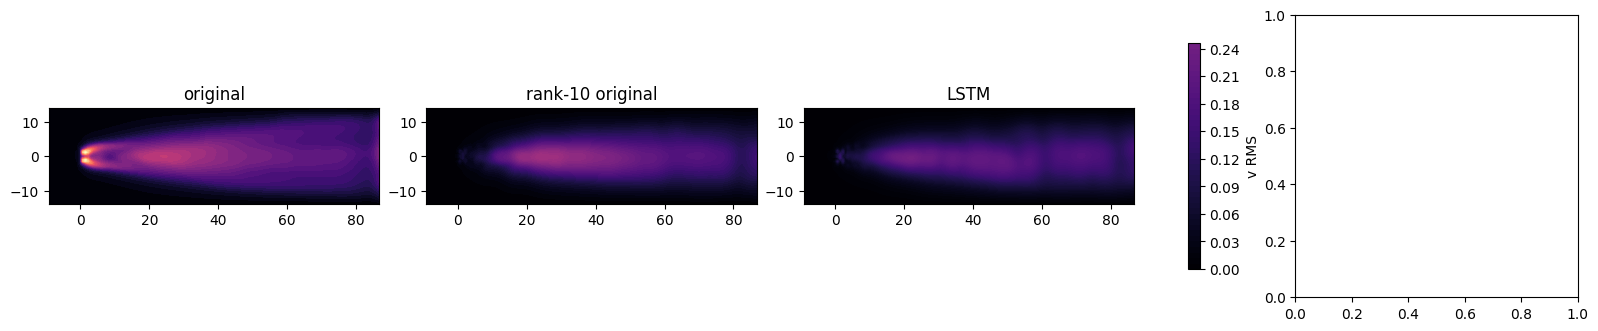

In [6]:
# Leading POD coefficients, as computed from Q2
r_pod= 10                                                                                                         # Rank, From the POD energy plot    
a= (S[:r_pod,None]*Vt[:r_pod,:]).T                                                                                # (r_pod, Nt) from S and Vt, then .T into (Nt, r_pod)
print(a.shape)

a_check= (U_pod[:,:r_pod].T@ Xf).T                                                                               # To check the same coefficients by direct projection of the data onto modes, U_pod[:,:r_pod].T @ Xf, then .T
print(np.allclose(a,a_check))

# Splitting the field in terms of time and normalising
ntr= 800                                                                                                          # To be chosen considering that LSTM requires several shedding periods per window and a test window

a_tr, a_te= a[:ntr],a[ntr:]
mu,sd= a_tr.mean(axis=0),a_tr.std(axis=0)                                                                                                  # Training statistics
a_tr_n, a_te_n = (a_tr-mu)/sd, (a_te - mu)/sd

def make_windows(seq,L):                                                                                          # Making windows from L past steps to next step
    Xw, Yw= [],[]
    for i in range(len(seq)-L):
        Xw.append(a_tr_n[i:i+L,:])                                                                                            # (L,r_pod)
        Yw.append(a_tr_n[i+L,:])                                                                                            # (r_pod,)
    return(torch.tensor(np.array(Xw), dtype= torch.float32),torch.tensor(np.array(Yw),dtype=torch.float32))
L= 18                                                                                                            # Comparing with shedding period
Xw, Yw=make_windows(a_tr_n,L)
print(Xw.shape, Yw.shape)
print(np.allclose(Xw[0],a_tr_n[:18]))
print(np.allclose(Yw[0],a_tr_n[18]))

class CoeffLSTM(nn.Module):
    def __init__(self, r_pod, hidden=64, layers=1):
        super().__init__()
        self.lstm= nn.LSTM(r_pod,hidden,layers,batch_first=True)
        self.fc= nn.Linear(hidden,r_pod)
    def forward(self,x):                                                                                   # input (batch, L, r_pod)
        out,_= self.lstm(x)                                                                                # out: (batch,L,hidden)
        return self.fc(out[:,-1,:])                                                                        # Returns only the last time step, which is used to predict the next timestep
lstm= CoeffLSTM(r_pod)
print(lstm(Xw[:5]).shape)

# Repeating the training loop (Similar to the training loop for the Autoencoder)
torch.manual_seed(0)
batch_size_lstm=100
loader= DataLoader(TensorDataset(Xw,Yw), batch_size=batch_size_lstm, shuffle= True)                                    # Shuffle=True to randomise training examples' order after each epoch
opt_1= torch.optim.Adam(lstm.parameters(),lr=3e-3)
loss_1= nn.MSELoss()
n_ep= 100                                                                                                # Number of epochs
hist_tr, hist_va= [],[]
Xva, Yva= make_windows(np.concatenate([a_tr_n[-L:],a_te_n]),L)                                           # Setting validation window on test period
for ep in range(n_ep):
    lstm.train(); run=0.0
    for xb, yb in loader:
        loss= loss_1(lstm(xb),yb)                                                                                         # Forward + loss
        opt_1.zero_grad();loss.backward();opt_1.step()                                                                        # Backward, step
        run+=loss.item()*xb.shape[0]
    hist_tr.append(run/len(Xw))
    lstm.eval()
    with torch.no_grad():
        hist_va.append(loss_1(lstm(Xva),Yva).item())
    if ep % 10==0:
        print(ep, hist_tr[-1], hist_va[-1])
plt.figure()
plt.semilogy(hist_tr,label='train')
plt.semilogy(hist_va,label='Test')
plt.xlabel('Number of Epochs'); plt.ylabel('MSE(Normalised)');plt.legend()
plt.grid(True)

# Forming closed loop prediction over the test period
def rollout(lstm,seed,nsteps):
    win= torch.as_tensor(seed,dtype=torch.float32).unsqueeze(0);preds=[]
    lstm.eval()
    with torch.no_grad():
        for _ in range (nsteps):
            nxt= lstm(win)                                                                            # Adding batch axis, ->numpy(r_pod,)
            preds.append(nxt.squeeze(0).cpu().numpy())
            win= torch.cat([win[:,1:,:],nxt.unsqueeze(1)],dim=1)                                      # Dropping old row and appending next
    return np.array(preds)
nte= 200
a_pred_n= rollout(lstm, a_tr_n[-L:],nte)                                                            # last L training points
a_pred= a_pred_n*sd+mu
#print(a_pred.shape)

n= np.arange(nte)
fig,ax= plt.subplots(4,1,figsize=(10,8),sharex=True)
for m in range(4):
    ax[m].plot(n,a_te_n[:,m],label='True')
    ax[m].plot(n,a_pred_n[:,m],label='LSTM')
    ax[m].set_ylabel(f'a_{m+1} (normalised)')
    ax[m].grid(True)
ax[0].legend(); ax[-1].set_label('steps into the rollout')

# Transforming back to physical space
Xhat_pred= Xbar+U_pod[:,:r_pod]@a_pred.T                                                    # Xhat with values predicted using LSTM 
Xhat_truth=Xbar+U_pod[:,:r_pod]@a_te.T                                                      # Xhat with true test coefficients
Xtrue=Xbar+Xf[:,ntr:]                      
print(Xhat_pred.shape,Xhat_truth.shape,Xtrue.shape)                                                 # Original Values

Un= U_pod[:,:r_pod]
X_true= Xbar+ Xf[:,ntr:]
X_trunc= Xbar+Un@a_te.T
X_lstm=Xbar+Un@a_pred.T

def to_u(Xcols,comp):
    n=Xcols.shape[1]
    return Xcols.T.reshape(n,128,64,2)[...,comp]
u_true,u_trunc,u_lstm=(to_u(X,0) for X in (X_true,X_trunc,X_lstm))
v_true,v_trunc,v_lstm=(to_u(X,1) for X in (X_true,X_trunc,X_lstm))

def mean_rms(f):
    m = f.mean(axis=0)                                 
    return m, np.sqrt(((f - m)**2).mean(axis=0))

S_l = {}
for name, (uf, vf) in {"Original": (u_true, v_true), "Original Truncated": (u_trunc, v_trunc),"LSTM": (u_lstm, v_lstm)}.items():
    S_l[name] = {"um": mean_rms(uf)[0], "ur": mean_rms(uf)[1],"vm": mean_rms(vf)[0], "vr": mean_rms(vf)[1]}

def row_l(key, label, cmap):
    F = [S_l[n][key] for n in ("Original", "Original Truncated", "LSTM")]
    vmin, vmax = min(f.min() for f in F), max(f.max() for f in F)
    fig, axs = plt.subplots(1, 4, figsize=(16, 3.2), constrained_layout=True)
    for axi, f, t in zip(axs[:3], F, ("original", f"rank-{r_pod} original", "LSTM")):
        im = axi.contourf(x, y, f, levels=40, cmap=cmap, vmin=vmin, vmax=vmax); axi.set_title(t)
    fig.colorbar(im, ax=axs[:3], shrink=0.8, label=label)
    d = F[2] - F[0]; dm = np.abs(d).max()
    #im2 = axs[3].contourf(x, y, d, levels=40, cmap="RdBu_r", vmin=-dm, vmax=dm); axs[3].set_title("LSTM - truth")
    #fig.colorbar(im2, ax=axs[3], shrink=0.8)
    for axi in axs: axi.set_aspect("equal")

row_l("um", "mean u", "viridis");  row_l("ur", "u RMS", "magma")
row_l("vm", "mean v", "RdBu_r");   row_l("vr", "v RMS", "magma")


# 5. Temporal dynamics using Poincare maps and Lyapunov exponents

54 11


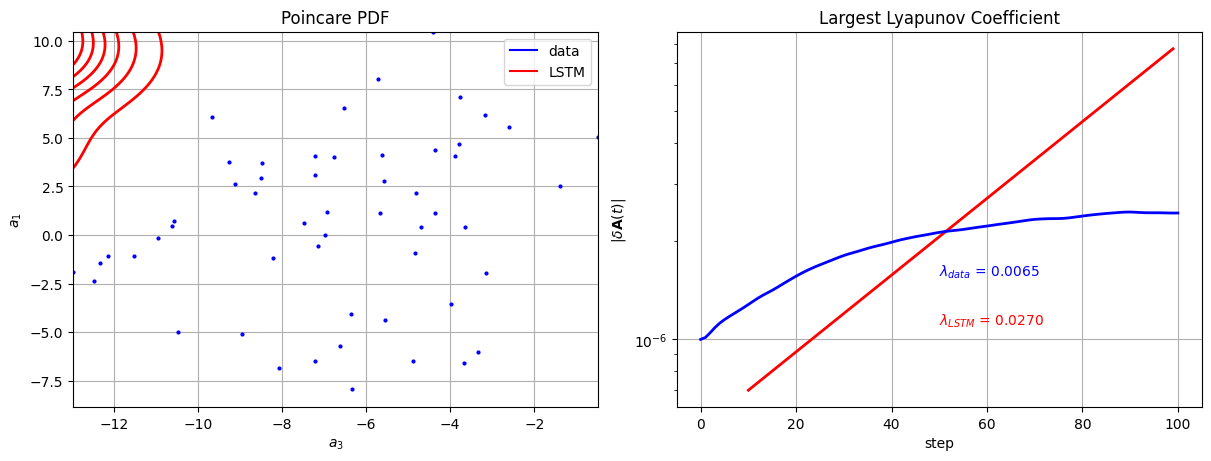

lamda per snapshot 0.0064556837073499775


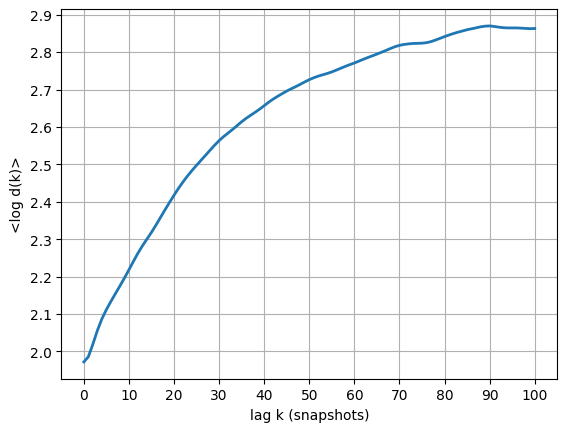

In [23]:
import copy,torch
from scipy.stats import gaussian_kde
from scipy.spatial.distance import cdist

n_long=20000
a_long_n= rollout(lstm,a_tr_n[-L:],n_long)                     # Normalised
a_long= a_long_n*sd +mu
a5= (S[:r_pod,None]*Vt[:r_pod,:]).T
dt = 1.0                                       # no physical dt given: state "per snapshot"

def poincare(traj, k_cross, k_section, level, direction=+1):
    pts = []
    for i in range(len(traj) - 1):
        c0, c1 = (traj[i, k_cross] - level)*direction, (traj[i+1, k_cross] - level)*direction
        if c0<0 and c1>=0:                                # sign change in the chosen direction
            w = -c0/(c1-c0)                            # interpolation fraction in [0, 1]
            p = (1-w)*traj[i]+ w*traj[i+1]                            # state at the crossing, (r,)
            pts.append(p[k_section])
    return np.array(pts)

P_true = poincare(a5,k_cross=0, k_section=[1,2], level=0.0)   
P_lstm = poincare(a_pred, k_cross=0, k_section=[1,2], level=0.0)   # un-normalised
print(len(P_true), len(P_lstm))

def density(P,gy,gx):
    GX,GY=np.meshgrid(gx,gy)
    return gaussian_kde(P.T)(np.vstack([GX.ravel(),GY.ravel()])).reshape(GX.shape)

allP= np.vstack([P_true,P_lstm])
gx= np.linspace(allP[:,0].min(),allP[:,0].max(),120)
gy= np.linspace(allP[0,1].min(),allP[:,1].max(),120)
Dt,D1=density(P_true,gx,gy),density(P_lstm,gx,gy)
lv=np.linspace(0,max(Dt.max(),D1.max()),8)[1:]

fig,ax=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
ax[0].plot(P_true[:,0],P_true[:,1],"b.",ms=4)
ax[0].contour(gx,gy,Dt,levels=lv,colors="b",linewidths=2)
ax[0].contour(gx,gy,D1,levels=lv,colors="r",linewidths=2)
ax[0].plot([],[],"b",label="data");ax[0].plot([],[],"r",label="LSTM");ax[0].legend()
ax[0].set_xlabel("$a_3$");ax[0].set_ylabel("$a_1$");ax[0].set_title("Poincare PDF"); ax[0].grid(True)


def Lyapunov_largest(traj, theiler, tmax):
    N = len(traj)
    d_all = cdist(traj,traj)                                         # pairwise distances (N, N) (scipy.spatial.distance.cdist)
    idx= np.arange(N)                                                # setting |i - j| <= theiler to +inf; nn = argmin per row
    d_all[np.abs(idx[:,None]-idx[None,:])<=theiler]=np.inf           # Excluding temporal neighbours
    nn= np.argmin(d_all,axis=1)                                      #nearest neighbour of each point, (N,)

    curve= np.zeros(tmax+1)
    for k in range(tmax+1):
        valid= (idx+k<N) & (nn+k<N)
        i=idx[valid]
        dist=np.linalg.norm(traj[i+k]-traj[nn[i]+k],axis=1)
        curve[k]= np.mean(np.log(dist[dist>0]))
    return curve                                                      # shape (tmax+1,)

lstm64= copy.deepcopy(lstm).double().eval()

# Calculating the Lyapunov Exponent of the LSTM model
def ly_diverge(model,starts,eps,nsteps,seed=0):
    ref,per=starts.clone(),starts.clone()
    g= torch.Generator().manual_seed(seed)
    d = torch.randn(starts.shape[0], starts.shape[2], dtype=torch.float64, generator=g)
    d= d/d.norm(dim=1, keepdim=True)                                            # Normalising each row to unit length
    per[:,-1,:]=per[:,-1,:]+ eps*d                                              # Perturb the newest state by size eps
    out=[(per[:,-1]-ref[:,-1]).norm(dim=1).numpy()]
    with torch.no_grad():
        for _ in range(nsteps):
            nr,npr= model(ref),model(per)
            ref= torch.cat([ref[:,1:,:], nr[:,None,:]],dim=1)
            per= torch.cat([per[:,1:,:],npr[:,None,:]],dim=1)
            out.append((npr-nr).norm(dim=1).cpu().numpy())
    return np.stack(out,axis=1)

ids= np.random.default_rng(0).integers(1000,n_long-L-1,size=100)
starts= torch.tensor(np.stack([a_long_n[i:i+L] for i in ids]),dtype=torch.float64)
dist=ly_diverge(lstm64,starts,eps=1e-6,nsteps=1500)
div,step=dist.mean(axis=0), np.arange(dist.shape[1])
k1,k2=10,100
fit = np.polyfit(step[k1:k2], np.log(div[k1:k2]), 1)
ax[1].semilogy(step[k1:k2], np.exp(np.polyval(fit, step[k1:k2])), "r",linewidth=2)
lam_lstm = fit[0] / dt

thelier=36; tmax=100
ly_curve = Lyapunov_largest(a5, theiler=thelier, tmax=tmax)  # Theiler window
# plotting ly_curve vs lag and fit a line to the LINEAR range only; slope / dt is lambda.
lag= np.arange(tmax+1)
# Fitting only the linear plot
kd1,kd2= 10,100
slope= np.polyfit(lag[k1:k2],ly_curve[k1:k2],1)[0]/dt
ax[1].semilogy(lag,np.exp(ly_curve-ly_curve[0]+np.log(div[0])),"b",linewidth=2)
ax[1].text(0.5, 0.35, f"$\\lambda_{{data}}$ = {slope:.4f}", color="b", transform=ax[1].transAxes)
ax[1].text(0.5, 0.22, f"$\\lambda_{{LSTM}}$ = {lam_lstm:.4f}", color="r", transform=ax[1].transAxes)
ax[1].set_xlabel("step"); ax[1].set_ylabel(r"$|\delta \mathbf{A}(t)|$")
ax[1].set_title("Largest Lyapunov Coefficient")
ax[1].grid(True);
plt.show()

fig,ax= plt.subplots()
ax.plot(lag,ly_curve,"", linewidth=2);ax.set_xlabel("lag k (snapshots)"); ax.set_ylabel("<log d(k)>")
ax.grid(True)
ax.xaxis.set_major_locator(MultipleLocator(10))
ax.yaxis.set_major_locator(MultipleLocator(0.1))

print('lamda per snapshot',slope/dt)


# 6. Using SINDy to identify the dynamics of the system and compare with the results above

[10, 35, 84, 286]


c:\Users\mksri\AppData\Local\Programs\Python\Python313\Lib\site-packages\pysindy\optimizers\stlsq.py:234: UserWarning: Sparsity parameter is too big (0.2848035868435799) and eliminated all coefficients
  warnings.warn(
c:\Users\mksri\AppData\Local\Programs\Python\Python313\Lib\site-packages\pysindy\optimizers\stlsq.py:234: UserWarning: Sparsity parameter is too big (0.2848035868435799) and eliminated all coefficients
  warnings.warn(
c:\Users\mksri\AppData\Local\Programs\Python\Python313\Lib\site-packages\pysindy\optimizers\stlsq.py:224: UserWarning: Sparsity parameter is too big (0.5336699231206307) and eliminated all coefficients
  warnings.warn(
c:\Users\mksri\AppData\Local\Programs\Python\Python313\Lib\site-packages\pysindy\optimizers\stlsq.py:224: UserWarning: Sparsity parameter is too big (1.0) and eliminated all coefficients
  warnings.warn(


(x0)' = -0.336 x1
(x1)' =  0.337 x0
(x2)' =  0.076 1 + -0.048 x0 + -0.316 x3 + -0.063 x0 x3 + -0.064 x1 x2 + -0.108 x3^2 +  0.066 x0^2 x3 +  0.057 x0 x3^2 +  0.023 x1^2 x3
(x3)' =  0.173 x2
SINDy linear eigenvalues: [0.00000000e+00+0.3361541j  0.00000000e+00-0.3361541j
 4.16333634e-17+0.23402468j 4.16333634e-17-0.23402468j]
frequenices (cycles/snapshot): [0.05350059 0.05350059 0.03724618 0.03724618]
True
method             peak RMS % vs truth  rel. L2 error of RMS field
Truth                0.4752       0.0%                       12.000
rank-4 truth:        0.1663     -65.0%                       12.000
SINDy                0.1584     -66.7%                       12.000
LSTM(4modes)         0.1348     -71.6%                       12.000


C:\Users\mksri\AppData\Local\Temp\ipykernel_4448\2564249836.py:99: UserWarning: The following kwargs were not used by contour: 'vim'
  im=axi.contourf(x,y,F[n],levels=40,cmap=cmap,vim=vmin,vmax=vmax)


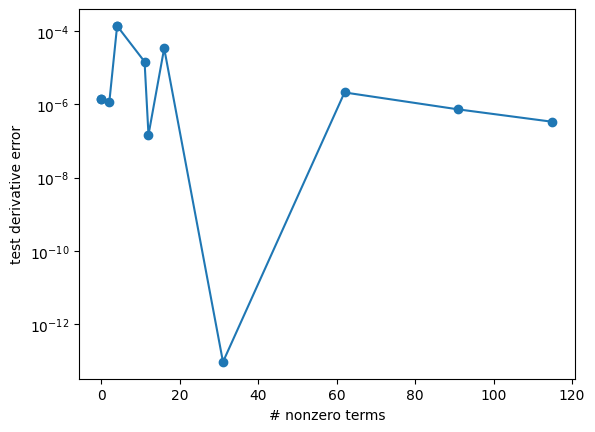

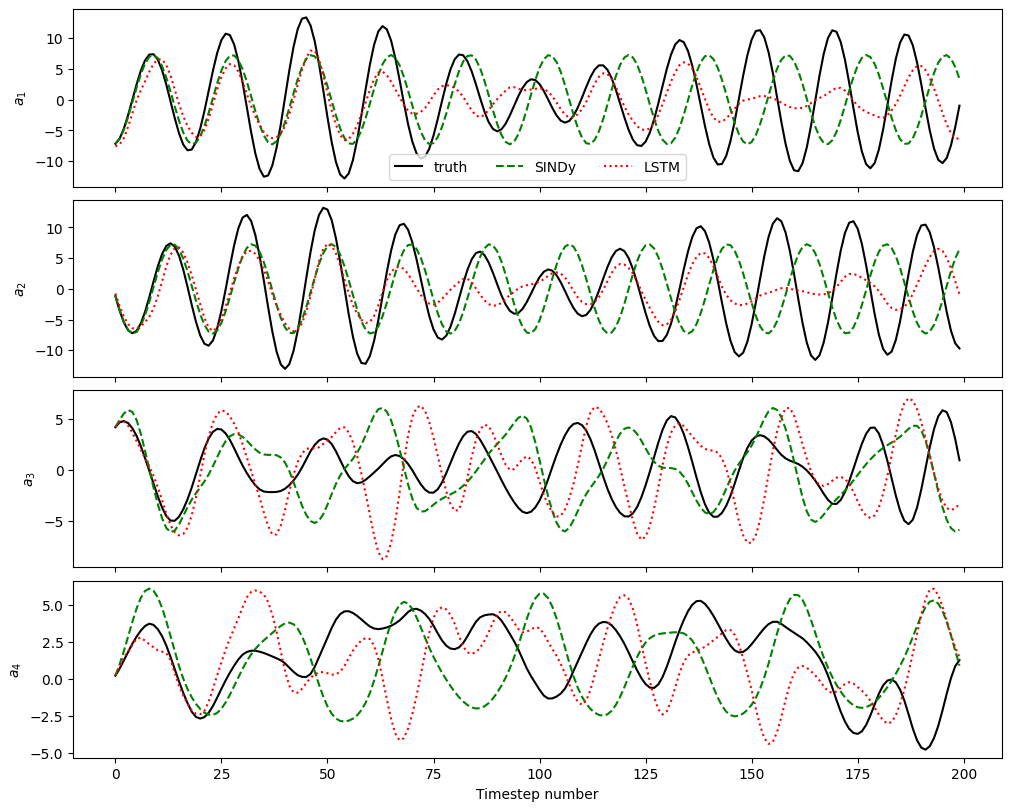

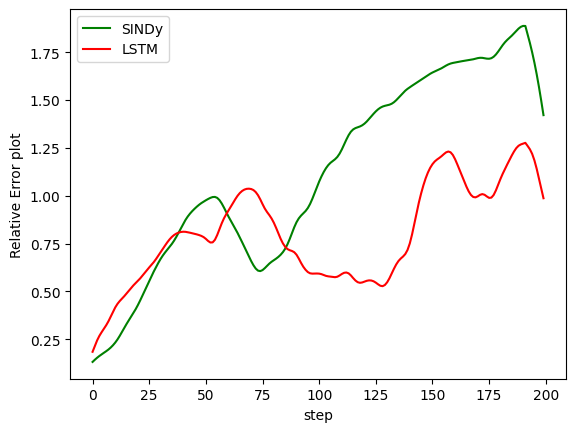

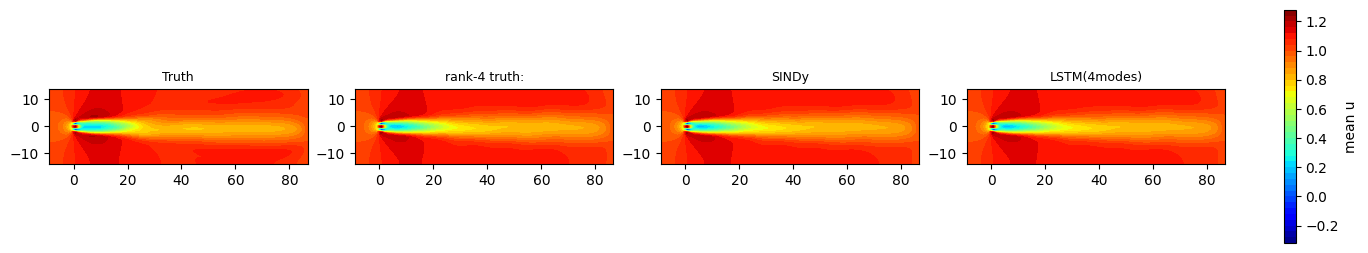

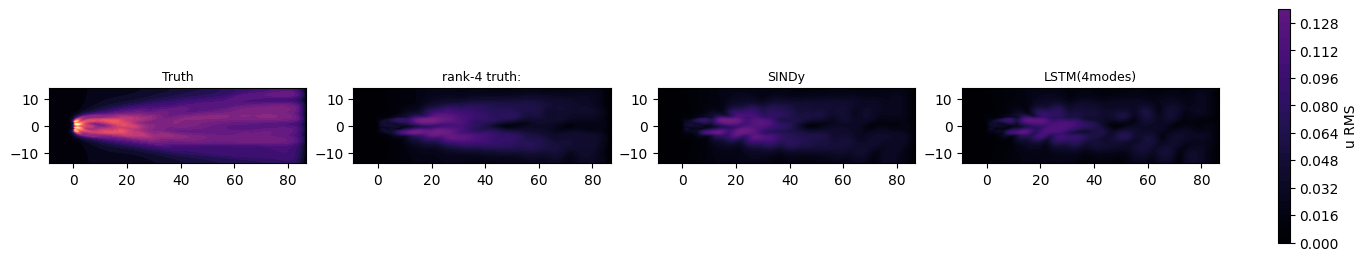

'\ndef sin_diverge(starts,eps,nsteps):\n    out=[]\n    rng= np.random.default_rng(0)\n    for s0 in starts:\n        d=rng.standard_normal(n_sin);d=d/np.linalg.norm(d)                         #Unit vector\n        ref=solve_ivp(rhs,[0,nsteps*dt],s0,t_eval=np.arange(nsteps+1)*dt,rtol=1e-10,atol=1e-12).y\n        per=solve_ivp(rhs,[0,nsteps*dt],s0+ eps*d,t_eval=np.arange(nsteps+1)*dt,rtol=1e-10,atol=1e-12).y\n        out.append(np.linalg.norm(per-ref,axis=0))\n    return np.mean(out,axis=0)\nprint(sin_diverge())\n'

In [24]:
import pysindy as ps
from scipy.integrate import solve_ivp
from math import comb
dt=1.0                                                                        # Timesteps, same as previous tasks
a6= (S[:r_pod,None]*Vt[:r_pod,:]).T
n_sin= 4                                                                      # Number of leading modes (start with 2 to 6)
print([comb(n+3,3) for n in (2,4,6,10)])                                      # Degree 3 library size vs 1000 samples

# Splitting the data field in terms of time 
sin_tr= a6[:ntr, :n_sin];sin_te= a6[ntr:,:n_sin]
sin_sd=sin_tr.std(axis=0)                                                     # per-mode scale from training only
sin_trn=sin_tr/sin_sd; sin_ten=sin_te/sin_sd

# Calculating the derivatives
sin_diff= ps.SmoothedFiniteDifference(smoother_kws={"window_length":7})    #Should be odd and >5
sin_dot= sin_diff._differentiate(sin_trn, t=dt)
lib= ps.PolynomialLibrary(degree=3)
def fit_sindy(thr,alpha=1e-3):
    opt=ps.STLSQ(threshold=thr,alpha=alpha)
    m=ps.SINDy(optimizer=opt,feature_library=lib,differentiation_method=sin_diff)
    m.fit(sin_trn, t=dt)
    return m
thrs= np.logspace(-3,0,12)
nnz,err_d=[],[]
for thr in thrs:
    m= fit_sindy(thr)
    nnz.append(int(np.count_nonzero(m.coefficients())))
    err_d.append(np.mean(np.mean(m.predict(sin_ten)-sin_diff(sin_ten))**2))                                               # derivative error on the test set

plt.figure();plt.semilogy(nnz,err_d,"o-");plt.xlabel("# nonzero terms"); plt.ylabel("test derivative error")

sin_model=fit_sindy(thrs[5])                                                                  # Threshold to be chosen
sin_model.print()

# Comparing the Linear part and DMD
Lin=sin_model.coefficients()[:,1:n_sin+1]                                                             # (n_sin X n_sin) block of coefficients multipying the linear terms
ev= np.linalg.eigvals(Lin)
print("SINDy linear eigenvalues:",ev)
print("frequenices (cycles/snapshot):", np.abs(ev.imag)/(2*np.pi))

# Simulating over the test period
sin_t= np.arange(nte)*dt
sin_sin=sin_model.simulate(sin_ten[0],sin_t)
sin_sim_phys= sin_sin*sin_sd

# PLotting the coefficients
k= np.arange(nte)
fig,ax= plt.subplots(n_sin,1,figsize=(10,2.0*n_sin),sharex=True, constrained_layout=True)
for m,axi in enumerate(ax):
    axi.plot(k,a_te[:,m],"k",label="truth")
    axi.plot(k,sin_sim_phys[:,m],"g--",label="SINDy")
    axi.plot(k,a_pred[:,m],"r:",label="LSTM")
    axi.set_ylabel(f"$a_{m+1}$")
ax[0].legend(ncol=3);ax[-1].set_xlabel("Timestep number")

# Plotting error vs horizon
def smooth_err(pred,truth, T=18):
    e2=np.sum((pred-truth)**2,axis=1)                           # Squared error over modes
    return np.sqrt(np.convolve(e2,np.ones(T)/T,mode="same"))    # RMS over T timesteps
sig= np.sqrt(np.sum(a_te[:,:n_sin]**2,axis=1).mean())           # Scaling signal size

def to_u(Xcols):
    n_t=Xcols.shape[1]
    return Xcols.T.reshape(n_t,128,64,2)[...,0]

def stats(f):
    mean=f.mean(axis=0)
    rms=np.sqrt(((f-mean)**2).mean(axis=0))
    return mean,rms

e_sin=smooth_err(sin_sim_phys[:,:n_sin],a_te[:,:n_sin])/sig      # Comparing SINDy vs truth for rank
e_lstm= smooth_err(a_pred[:,:n_sin],a_te[:,:n_sin])/sig          # Comparing LSTM vs truth
plt.figure()
plt.plot(k,e_sin,"g",label="SINDy"); plt.plot(k,e_lstm,"r",label="LSTM")
plt.xlabel("step"); plt.ylabel("Relative Error plot");plt.legend()

# Reconstructing flow field from each physical set
Un= U_pod[:,:n_sin]
X_true= Xbar+Xf[:,ntr:]                                        # Original test snapshots
X_trunc= Xbar+Un@a_te[:,:n_sin].T                              # rank-n_sin with True coefficients
X_sin= Xbar+Un@sin_sim_phys[:,:n_sin].T                        # Reconstruction from SINDy coefficients
X_lstm= Xbar+Un@a_pred[:,:n_sin].T                             # Reconstruction from LSTM coefficients

fields={"Truth":X_true,f"rank-{n_sin} truth:":X_trunc,"SINDy":X_sin,f"LSTM({n_sin}modes)":X_lstm}
u_f={name: to_u(X) for name,X in fields.items()}
print(np.allclose(u_f["Truth"],u[ntr:]))

# PLotting contour rows: mean and RMS

m_f,r_f={},{}
for name,f in u_f.items():
    m_f[name],r_f[name]=stats(f)

def contour_row(F,label,cmap):
    names=list(F)
    vmin=min(F[n].min() for n in names); vmax=max(F[n].max() for n in names)
    fig,axs= plt.subplots(1,len(names),figsize=(3.4*len(names),3.0),constrained_layout=True)
    for axi,n in zip(axs,names):
        im=axi.contourf(x,y,F[n],levels=40,cmap=cmap,vim=vmin,vmax=vmax)
        axi.set_title(n,fontsize=9);axi.set_aspect("equal")
    fig.colorbar(im,ax=axs,shrink=0.8,label=label)
contour_row(m_f,"mean u","jet")
contour_row(r_f,"u RMS","magma")                               

ref="Truth"
print(f"{'method':18s}{'peak RMS':>9s}{'% vs truth':>11s}{'rel. L2 error of RMS field':>28s}")
for name in r_f:
    pk=r_f[name].max()
    pct=100*(pk-r_f[ref].max())/r_f[ref].max()
    l2=np.linalg.norm(r_f[name]-r_f[ref])/np.linalg.norm(r_f[ref])
    print(f"{name:18s}{pk:9.4f}{pct:10.1f}% {12:28.3f}")
plt.show()

# Lyapunov coefficient of SINDy model
def rhs(t,s):
    return sin_model.predict(s[None,:])[0]
"""
def sin_diverge(starts,eps,nsteps):
    out=[]
    rng= np.random.default_rng(0)
    for s0 in starts:
        d=rng.standard_normal(n_sin);d=d/np.linalg.norm(d)                         #Unit vector
        ref=solve_ivp(rhs,[0,nsteps*dt],s0,t_eval=np.arange(nsteps+1)*dt,rtol=1e-10,atol=1e-12).y
        per=solve_ivp(rhs,[0,nsteps*dt],s0+ eps*d,t_eval=np.arange(nsteps+1)*dt,rtol=1e-10,atol=1e-12).y
        out.append(np.linalg.norm(per-ref,axis=0))
    return np.mean(out,axis=0)
print(sin_diverge())
"""